In [1]:
from pathlib import Path

import numpy as np
from dataeval.data import Filter, Limit, Shuffle, View
from datamaite import load_ic
from maite_datasets.image_classification import MilitaryVehicles

data_root = Path("./data")
MilitaryVehicles(root=data_root, image_set="base", download=True)
MilitaryVehicles(root=data_root, image_set="train", as_datamaite=True)

vehicles_raw = load_ic(data_root / "militaryvehicles_datamaite_train" / "train", dataset_format="huggingface_vision")
index2label = vehicles_raw.metadata.get("index2label", {})

# The category this collection cycle never captured.
AIR_DEFENSE = {"30N6E", "Iskander", "Pantsir-S1", "Rs-24"}
collected_classes = [i for i, name in index2label.items() if name not in AIR_DEFENSE]

# `Filter` enforces the gap by filtering on sample labels.
# `Shuffle` and `Limit` sample the result for faster execution.
collected = View(vehicles_raw, [Filter(classes=collected_classes), Shuffle(seed=0), Limit(1500)])

print(f"Full collection:  {len(vehicles_raw)} frames, {len(index2label)} types")
print(f"After the gap:    {len(collected)} frames, {len(collected_classes)} types")
print(f"Never collected:  {sorted(AIR_DEFENSE)}")

/builds/jatic/aria/dataeval-flow/.nox/docs/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Full collection:  7823 frames, 24 types
After the gap:    1500 frames, 20 types
Never collected:  ['30N6E', 'Iskander', 'Pantsir-S1', 'Rs-24']


In [2]:
labels = np.array([int(np.argmax(collected[i][1])) for i in range(len(collected))])
class_counts = {index2label[c]: int((labels == c).sum()) for c in sorted(set(labels.tolist()))}
ordered = sorted(class_counts.items(), key=lambda kv: -kv[1])

largest, smallest = ordered[0], ordered[-1]
ratio = largest[1] / smallest[1]
print(f"Largest class:  {largest[0]} ({largest[1]})")
print(f"Smallest class: {smallest[0]} ({smallest[1]})")
print(f"Imbalance ratio: {ratio:.2f}:1")

Largest class:  BTR-80 (94)
Smallest class: T-90 (53)
Imbalance ratio: 1.77:1


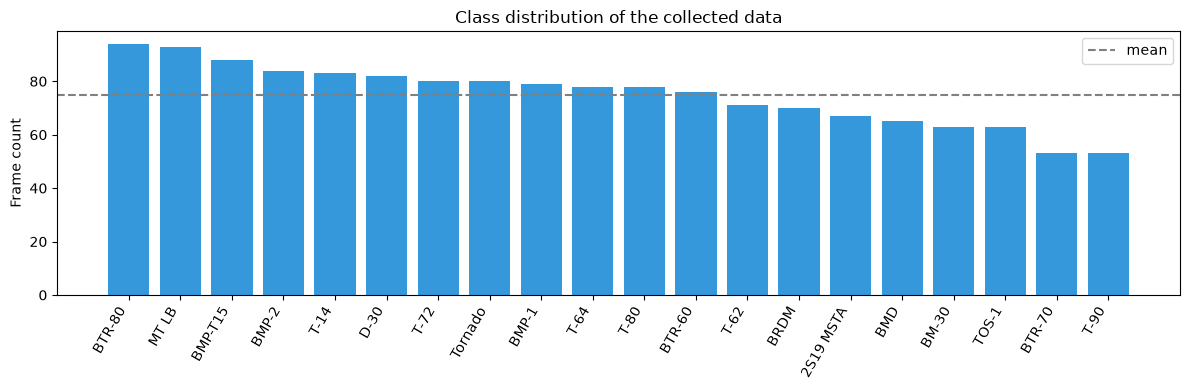

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
names = [n for n, _ in ordered]
values = [v for _, v in ordered]
ax.bar(names, values, color="#3498db")
ax.axhline(y=float(np.mean(values)), color="gray", linestyle="--", label="mean")
ax.set_ylabel("Frame count")
ax.set_title("Class distribution of the collected data")
ax.tick_params(axis="x", rotation=60)
for tick in ax.get_xticklabels():
    tick.set_horizontalalignment("right")
ax.legend()
plt.tight_layout()
plt.show()

In [4]:
from dataeval_flow import run_task, run_tasks
from dataeval_flow.config import DatasetProtocolConfig, MetadataPolicyConfig, PipelineConfig, SourceConfig, TaskConfig
from dataeval_flow.workflows.bias import BiasConfig
from dataeval_flow.workflows.scope import ScopeConfig

vehicle_factors = MetadataPolicyConfig(
    name="vehicle_factors",
    # Nothing in this dataset's own per-sample metadata is a collection condition:
    # `id` is unique per frame (so it looks perfectly class-predictive) and height and
    # width describe the crop, not the scene. Ask for measured image statistics instead.
    intrinsic_factors=["visual", "pixel"],
    exclude=["id", "height", "width"],
    # Explicitly declared bins keep factor cuts consistent across runs.
    continuous_factor_bins={
        "brightness": 5,
        "contrast": 5,
        "darkness": 5,
        "entropy": 5,
        "kurtosis": 5,
        "mean": 5,
        "sharpness": 5,
        "skew": 5,
        "std": 5,
        "var": 5,
        "zeros": 5,
    },
)

bias_workflow = BiasConfig.model_validate(
    {
        "name": "bias",
        "metadata": "vehicle_factors",
        "factor-gaps": {"min_representation": 5},  # Flag class-factor-value combos with < 5 samples
        "diversity": {"method": "simpson"},
        "checks": {
            "class-imbalance": {"warning": 3.0},  # Catch moderate class imbalance
            "factor-coverage-gaps": {"warning": 2},  # Warn past 2 gaps
        },
    }
)
metadata_only_workflow = ScopeConfig(name="coverage-metadata-only")

task_bias = TaskConfig(name="vehicles-bias", workflow="bias", sources="vehicles_src")
task_metadata = TaskConfig(
    name="vehicles-coverage-metadata",
    workflow="coverage-metadata-only",
    sources="vehicles_src",
    # No extractor for metadata-only pass
)

config_metadata = PipelineConfig(
    max_processes=2,
    metadata=[vehicle_factors],
    datasets=[
        DatasetProtocolConfig(name="vehicles_collected", format="maite", dataset=collected),
    ],
    sources=[
        SourceConfig(name="vehicles_src", dataset="vehicles_collected"),
    ],
    workflows=[bias_workflow, metadata_only_workflow],
    tasks=[task_bias, task_metadata],
)

In [5]:
results = run_tasks(config_metadata, cache_dir=Path("./cache"))
result_bias, result_metadata = results["vehicles-bias"], results["vehicles-coverage-metadata"]

/builds/jatic/aria/dataeval-flow/src/dataeval_flow/_chain/_run.py:176: ExperimentalWarning: The 'parity' evaluator is experimental: it may change or be removed in any release without a deprecation cycle.
  warn_if_experimental(step)
/builds/jatic/aria/dataeval-flow/src/dataeval_flow/_chain/_run.py:176: ExperimentalWarning: The 'factor-parity' check is experimental: it may change or be removed in any release without a deprecation cycle.
  warn_if_experimental(step)


/builds/jatic/aria/dataeval-flow/src/dataeval_flow/_cache.py:273: UserWarning: Declared cuts left bins unused: kurtosis (4 of 5 bins hold rows). The encoding still applies and the codes are unchanged; this is the data no longer matching the policy, not an error. Call reencode() to refit — which moves codes — or leave it and read the empty groups as the finding they are.
  export(path)


/builds/jatic/aria/dataeval-flow/src/dataeval_flow/evaluators/bias/_evaluator.py:92: ExperimentalWarning: 'Parity' is experimental and may change or be removed in any future release without notice.
  return Parity(**dataeval_arguments(config)).evaluate(metadata)
/builds/jatic/aria/dataeval-flow/.nox/docs/lib/python3.11/site-packages/dataeval/bias/_parity.py:478: ExperimentalWarning: 'parity' is experimental and may change or be removed in any future release without notice.
  result = parity(factor_data, axis.values, unit.groups, assume_independent=unit.groups is None)
/builds/jatic/aria/dataeval-flow/.nox/docs/lib/python3.11/site-packages/dataeval/bias/_parity.py:601: ExperimentalWarning: 'ParityOutput' is experimental and may change or be removed in any future release without notice.
  return ParityOutput(


/builds/jatic/aria/dataeval-flow/src/dataeval_flow/_cache.py:273: UserWarning: `height` and `width` were binned automatically ('uniform_width') because no bins were declared. The bin count is derived from the data, so it is not stable across samples and the same factor measured twice may not be comparable. Declare cutoffs with continuous_factor_bins={"height": [...]} to control this.
  export(path)


In [6]:
print(result_bias.report())


  BIAS
  Workflow:  bias
  Timestamp: 2026-11-01T16:57:00.610943+00:00
  Duration:  13.74s
  Source:    vehicles_src (vehicles_collected)

  Steps: 10 ran

  SUMMARY
  Class Imbalance .............. 24 classes, 1500 items, imbalance 1.8:1  [!!]
  Shortcut Risk ..................................... 12 factors checked  [ok]
  Factor Parity .................... 12 factors checked, 11 not assessed  [..]
  Parity Collection Gaps ................... 331 cells too thin to judge  [..]
  Factor Coverage Gaps .................... No significant gaps detected  [ok]

  Health: 1 warning(s) [!!] — review flagged findings

  CLASS IMBALANCE                        24 classes, 1500 items, imbalance 1.8:1
  Class       Count  Share
  ----------  -----  -----  ------------------------------
  BTR-80         94   6.3%  ██████████████████████████████
  MT LB          93   6.2%  █████████████████████████████▋
  BMP-T15        88   5.9%  ████████████████████████████▏
  BMP-2          84   5.6%  ███████████

In [7]:
print(result_metadata.report())


  SCOPE
  Workflow:  coverage-metadata-only (scope)
  Timestamp: 2026-11-01T16:57:01.251825+00:00
  Duration:  0.50s
  Source:    vehicles_src (vehicles_collected)

  Steps: 7 (5 ran, 2 skipped)

  SUMMARY
  Class Coverage .......................................... not assessed  [..]
  Dimensional Completeness ................................ not assessed  [..]
  Class Shortfall ........................ 6 classes short · deficit 266  [..]

  Health: All checks passed [ok]

  CLASS COVERAGE                                                    not assessed
  Not assessed: `coverage` was skipped: requires an extractor.

  From Coverage — skipped
    Skipped: requires an extractor

  DIMENSIONAL COMPLETENESS                                          not assessed
  Not assessed: `completeness` was skipped: requires an extractor.

  From Completeness — skipped
    Skipped: requires an extractor

  CLASS SHORTFALL                                  6 classes short · deficit 266
  6 class(es) fall

In [8]:
label_health = result_bias.steps["label-health"].output.data()
print(f"Number of classes: {label_health['class_count']}")
print(f"Empty images: {label_health['empty_image_count']}")
print("\nClass distribution (five largest, five smallest):")
by_size = sorted(label_health["label_counts_per_class"].items(), key=lambda x: x[1], reverse=True)
for cls, count in by_size[:5]:
    print(f"  {cls:<26} {count}")
print("  ...")
for cls, count in by_size[-5:]:
    print(f"  {cls:<26} {count}")

Number of classes: 24
Empty images: 0

Class distribution (five largest, five smallest):
  BTR-80                     94
  MT LB                      93
  BMP-T15                    88
  BMP-2                      84
  T-14                       83
  ...
  T-90                       53
  30N6E                      0
  Iskander                   0
  Pantsir-S1                 0
  Rs-24                      0


In [9]:
# Metadata gaps: evaluate if a class was only imaged under narrow conditions
gaps = result_bias.steps["factor-gaps"].output
print(f"Metadata coverage gaps: {len(gaps.gaps)}\n")

print("  Mutual information (class -> factor), five strongest:")
mi = sorted(gaps.mutual_information.items(), key=lambda x: -x[1])
for factor, value in mi[:5]:
    print(f"    {factor:<28} {value:.4f}")

print("\n  Gap details (first ten):")
for gap in gaps.gaps[:10]:
    print(
        f"    {gap.class_name:<14} x {gap.factor_name}={gap.factor_value}: "
        f"count={gap.class_count}, expected={gap.expected_count:.1f}, "
        f"deficit={gap.deficit:.0%}"
    )
if not gaps.gaps:
    print("    No metadata gaps detected.")

Metadata coverage gaps: 0

  Mutual information (class -> factor), five strongest:
    contrast                     0.0027
    mean                         0.0026
    brightness                   0.0024
    darkness                     0.0023
    entropy                      0.0020

  Gap details (first ten):
    No metadata gaps detected.


In [10]:
# The class worklist: each class short of an even spread over the declared classes
worklist = result_metadata.steps["representation"].output
print(f"Total deficit: {worklist.total_deficit} labels\n")
for row in worklist.data().iter_rows(named=True):
    print(f"  {row['label']:>14}  {row['action']:<8} have {row['count']:>4}, want {row['target']:>4}")

Total deficit: 266 labels

           30N6E  acquire  have    0, want   62
        Iskander  acquire  have    0, want   62
      Pantsir-S1  acquire  have    0, want   62
           Rs-24  acquire  have    0, want   62
          BTR-70  augment  have   53, want   62
            T-90  augment  have   53, want   62


In [11]:
import json

print(json.dumps(MilitaryVehicles.hierarchy, indent=2)[:900] + "\n...")

{
  "vehicle": {
    "military": {
      "land vehicle": {
        "Tank": [
          "T-14",
          "T-62",
          "T-64",
          "T-72",
          "T-80",
          "T-90"
        ],
        "BMP": [
          "BMP-1",
          "BMP-2",
          "BMP-T15"
        ],
        "BTR": [
          "BRDM",
          "BTR-60",
          "BTR-70",
          "BTR-80"
        ],
        "Self Propelled Artillery": [
          "2S19 MSTA",
          "BM-30",
          "D-30",
          "Tornado",
          "TOS-1"
        ],
        "Air Defense": [
          "30N6E",
          "Iskander",
          "Pantsir-S1",
          "Rs-24"
        ],
        "MT LB": [
          "MT LB"
        ],
        "BMD": [
          "BMD"
        ]
      },
      "watercraft": null,
      "aircraft": null
    }
  }
}
...


In [12]:
from dataeval_flow.workflows.taxonomy import TaxonomyConfig

vehicle_ontology = MilitaryVehicles.hierarchy

vocab_workflow = TaxonomyConfig(name="vocab", ontology=vehicle_ontology)

task_vocab = TaskConfig(
    name="vehicles-vocab",
    workflow="vocab",
    sources="vehicles_src",  # the source scope read
)

config_vocab = PipelineConfig(
    max_processes=2,
    datasets=config_metadata.datasets,
    sources=config_metadata.sources,
    workflows=[vocab_workflow],
    tasks=[task_vocab],
)

result_vocab = run_task(config_vocab, task_vocab, cache_dir=Path("./cache"))
print(result_vocab.report())


  TAXONOMY
  Workflow:  vocab (taxonomy)
  Timestamp: 2026-11-01T16:57:01.687349+00:00
  Duration:  0.07s
  Source:    vehicles_src (vehicles_collected)

  Steps: 8 ran

  SUMMARY
  Leaf Coverage ....... leaf coverage 76.9% · 6 to acquire · deficit 358  [!!]
  Label Conformance ........................................... conforms  [ok]
  Label Mergeability ..................................................   [ok]
  Ontology
  Structure ..... 34 concepts, 26 leaves, depth 4 · 1 single-child links  [..]

  Health: 1 warning(s) [!!] — review flagged findings

  LEAF COVERAGE                 leaf coverage 76.9% · 6 to acquire · deficit 358
  76.9% of the ontology's sanctioned leaf species have examples. The dataset is
  358 labels short of an even spread across them.

  Wholly-empty branches: Air Defense (4 leaves).

  Concept      Action  Count  Target  Deficit
  ----------  -------  -----  ------  -------
  30N6E       acquire      0      58       58
  Iskander    acquire      0      58

In [13]:
representation = result_vocab.steps["representation"].output
print(f"leaf coverage: {representation.leaf_coverage:.1%}")
print(f"total deficit: {representation.total_deficit} labels\n")

print("Dark branches: whole regions of the label space with zero examples:")
for branch in representation.dark_branches.iter_rows(named=True):
    print(f"  {branch['label']:<16} {branch['leaves']} leaf class(es), zero examples")

print("\nTop of the collection worklist:")
for row in representation.data().head(8).iter_rows(named=True):
    print(f"  {row['label']:>14}  {row['action']:<8} have {row['count']:>4}, want {row['target']:>4}")

leaf coverage: 76.9%
total deficit: 358 labels

Dark branches: whole regions of the label space with zero examples:
  Air Defense      4 leaf class(es), zero examples

Top of the collection worklist:
           30N6E  acquire  have    0, want   58
        Iskander  acquire  have    0, want   58
      Pantsir-S1  acquire  have    0, want   58
           Rs-24  acquire  have    0, want   58
        aircraft  acquire  have    0, want   58
      watercraft  acquire  have    0, want   58
          BTR-70  augment  have   53, want   58
            T-90  augment  have   53, want   58


In [14]:
from dataeval import Ontology
from dataeval.core import label_reconciliation

# `taxonomy` builds this from its `ontology` field. You can also construct the
# object directly to reconcile arbitrary label lists against it.
ontology_obj = Ontology.from_hierarchy(vehicle_ontology)
check = label_reconciliation(["T-72", "BTR-80", "T72", "technical"], ontology_obj)
print("matched:  ", dict(check["matched"]))
print("unmatched:", list(check["unmatched"]))

matched:   {'T-72': 'T-72', 'BTR-80': 'BTR-80'}
unmatched: ['T72', 'technical']


In [15]:
from dataeval_flow.config.extractors import BoVWExtractorConfig

full_workflow = ScopeConfig.model_validate(
    {
        "name": "coverage-full",
        "coverage": {
            "method": "adaptive",
            "percent": 0.01,  # adaptive: flag the sparsest 1% of observations
            "num_observations": 50,  # Number of neighbors for coverage analysis
        },
        "checks": {
            "dimensional-completeness": {"warning": 0.5},  # Warn if completeness < 0.5
        },
    }
)

task_full = TaskConfig(
    name="vehicles-coverage-full",
    workflow="coverage-full",
    sources="vehicles_src",
    extractor="bovw_ext",
)

config_full = PipelineConfig(
    max_processes=2,
    seed=0,
    metadata=config_metadata.metadata,
    datasets=config_metadata.datasets,
    sources=config_metadata.sources,
    extractors=[
        BoVWExtractorConfig(name="bovw_ext", vocab_size=256, batch_size=32),
    ],
    workflows=[full_workflow],
    tasks=[task_full],
)

In [16]:
result_full = run_task(config_full, task_full, cache_dir=Path("./cache"))

/builds/jatic/aria/dataeval-flow/.nox/docs/lib/python3.11/site-packages/dataeval/_embeddings.py:566: UserWarning: BoVWExtractor is fitting its vocabulary on the data of this one call. Inside Embeddings, Duplicates or Outliers that call is a single batch of batch_size images, not the whole dataset, and every later batch is encoded with that vocabulary. Call fit() on the images you want the vocabulary learned from, then pass the fitted extractor. This warning is not raised once the extractor is fitted.
  embeddings = self._rows(self._extractor(batch_images), len(batch_idx))


In [17]:
print(result_full.report(detailed=False))


  SCOPE
  Workflow:  coverage-full (scope)
  Timestamp: 2026-11-01T16:57:54.212430+00:00
  Duration:  52.45s
  Source:    vehicles_src (vehicles_collected)
  Model:     bovw_ext (bovw)

  Steps: 7 ran

  SUMMARY
  Class Coverage ................................... 15 uncovered (1.0%)  [..]
  Dimensional Completeness ......................... Completeness: 0.572  [..]
  Class Shortfall ........................ 6 classes short · deficit 266  [..]

  Health: All checks passed [ok]

  STEPS
  Step                      Status  Note
  ------------------------  ------  ----
  crops                     ok
  coverage                  ok
  class-coverage            ok
  completeness              ok
  dimensional-completeness  ok
  representation            ok
  class-shortfall           ok

  METADATA FACTORS
  Diagnostics
    - UserWarning: dataeval: BoVWExtractor is fitting its vocabulary on the data
      of this one call. Inside Embeddings, Duplicates or Outliers that call is a
      single

In [18]:
import polars as pl

coverage = result_full.steps["coverage"].output
per_class = coverage.data()
total = int(per_class["count"].sum())
uncovered = len(coverage.uncovered_indices)
print(f"Method: {full_workflow.coverage.method}")
print(f"Uncovered: {uncovered} of {total} ({uncovered / total:.1%})\n")

columns = ["class", "count", "uncovered", "dispersion", "isotropy", "near_duplicate_fraction"]
flags = ["is_clustered", "is_one_dimensional", "has_near_duplicates"]
with pl.Config(tbl_rows=-1, tbl_hide_dataframe_shape=True, tbl_hide_column_data_types=True, float_precision=2):
    print(per_class.select(columns).sort("dispersion"))
    print(per_class.select("class", *flags).sort("class"))

Method: adaptive
Uncovered: 15 of 1500 (1.0%)

┌───────────┬───────┬───────────┬────────────┬──────────┬─────────────────────────┐
│ class     ┆ count ┆ uncovered ┆ dispersion ┆ isotropy ┆ near_duplicate_fraction │
╞═══════════╪═══════╪═══════════╪════════════╪══════════╪═════════════════════════╡
│ T-72      ┆ 80    ┆ 0         ┆ 0.96       ┆ null     ┆ 0.00                    │
│ T-90      ┆ 53    ┆ 1         ┆ 0.97       ┆ null     ┆ 0.00                    │
│ BRDM      ┆ 70    ┆ 1         ┆ 0.98       ┆ null     ┆ 0.00                    │
│ 2S19 MSTA ┆ 67    ┆ 0         ┆ 0.99       ┆ null     ┆ 0.00                    │
│ BMP-1     ┆ 79    ┆ 0         ┆ 0.99       ┆ null     ┆ 0.00                    │
│ BTR-80    ┆ 94    ┆ 1         ┆ 0.99       ┆ null     ┆ 0.00                    │
│ T-64      ┆ 78    ┆ 0         ┆ 1.00       ┆ null     ┆ 0.00                    │
│ BM-30     ┆ 63    ┆ 1         ┆ 1.00       ┆ null     ┆ 0.00                    │
│ MT LB     ┆ 93    ┆ 1      

In [19]:
completeness = result_full.steps["completeness"].output.data()
print("Dimensional Completeness:")
print(f"  Score: {completeness['completeness']:.3f}")
print(f"  Nearest neighbor pairs: {len(completeness['nearest_neighbor_pairs'])}")

Dimensional Completeness:
  Score: 0.572
  Nearest neighbor pairs: 1435


In [20]:
from dataeval_flow.workflows.scope import ScopeChecks

strict_thresholds = ScopeChecks.model_validate({"dimensional-completeness": {"warning": 0.6}})
strict_coverage = full_workflow.coverage.model_copy(
    update={"dispersion_factor": 0.7, "isotropy_factor": 0.7, "near_duplicate_threshold": 0.02}
)

strict_workflow = full_workflow.model_copy(
    update={"name": "coverage-strict", "checks": strict_thresholds, "coverage": strict_coverage},
)

task_strict = TaskConfig(
    name="vehicles-coverage-strict",
    workflow="coverage-strict",
    sources="vehicles_src",
    extractor="bovw_ext",
)

config_strict = PipelineConfig(
    max_processes=2,
    seed=0,
    metadata=config_full.metadata,
    datasets=config_full.datasets,
    sources=config_full.sources,
    extractors=config_full.extractors,
    workflows=[full_workflow, strict_workflow],
    tasks=[task_strict],
)

result_strict = run_task(config_strict, task_strict, cache_dir=Path("./cache"))
print(result_strict.report(detailed=False))


  SCOPE
  Workflow:  coverage-strict (scope)
  Timestamp: 2026-11-01T16:57:55.805382+00:00
  Duration:  1.06s
  Source:    vehicles_src (vehicles_collected)
  Model:     bovw_ext (bovw)

  Steps: 7 ran

  SUMMARY
  Class Coverage ................................... 15 uncovered (1.0%)  [..]
  Dimensional Completeness ......................... Completeness: 0.572  [!!]
  Class Shortfall ........................ 6 classes short · deficit 266  [..]

  Health: 1 warning(s) [!!] — review flagged findings

  STEPS
  Step                      Status  Note
  ------------------------  ------  ----
  crops                     ok
  coverage                  ok
  class-coverage            ok
  completeness              ok
  dimensional-completeness  ok
  representation            ok
  class-shortfall           ok

  CONFIGURATION
  sources:
    - name: vehicles_src
      dataset: vehicles_collected
      dataset_config:
        name: vehicles_collected
        format: maite
        version: 1
   

In [21]:
for default, strict in zip(result_full.findings, result_strict.findings, strict=True):
    print(f"{default.title:<28} {default.severity:<8} -> {strict.severity:<8} {strict.brief}")

Class Coverage               info     -> info     15 uncovered (1.0%)
Dimensional Completeness     info     -> warning  Completeness: 0.572
Class Shortfall              info     -> info     6 classes short · deficit 266


In [22]:
json_str = result_full.export(fmt="json")
print(f"JSON output: {len(json_str)} characters")
print(json_str[:500] + "\n...")

JSON output: 228877 characters
{
  "kind": "workflow",
  "metadata": {
    "version": "1.0",
    "timestamp": "2026-11-01T16:57:54.212430Z",
    "dataset_id": "vehicles_collected",
    "label_source": "protocol",
    "model_id": "bovw_ext (bovw)",
    "preprocessor_id": null,
    "selection_id": null,
    "source_descriptions": [
      "vehicles_src (vehicles_collected)"
    ],
    "resolved_config": {
      "sources": [
        {
          "name": "vehicles_src",
          "dataset": "vehicles_collected",
          "dataset_
...
